# GreenPod Labs — Image Classification Assignment (Dataset Audit + Two Models)

**Important dataset note:** The supplied archive is named `Orange Dataset.zip` and contains `train/` and `test/` folders with four classes: `blackspot`, `canker`, `fresh`, and `grenning`. This is an **orange condition/disease classification dataset**, not an avocado-ripening dataset. This notebook uses the labels actually present in the uploaded archive. Before submission, verify with the recruiter whether this is the intended dataset for the avocado-ripening brief.

## Objective
Build an end-to-end image-classification workflow and compare:
1. **Classical computer vision:** HOG image features + an SVM classifier.
2. **Deep learning:** MobileNetV2 transfer learning.

The notebook inspects class balance, evaluates both models on the provided test set, plots confusion matrices, and generates evidence-based answers for the assignment questions. Run all cells from top to bottom in Google Colab. A GPU runtime is recommended for the transfer-learning model.


## 1. Set up the runtime

In Google Colab, select **Runtime → Change runtime type → T4 GPU** if available. If you are using your own machine, install the listed packages first. This notebook does not assume that any accuracy result is known in advance; all metrics are computed from the dataset when you run it.

In [1]:
!pip -q install scikit-image scikit-learn seaborn tensorflow


## 2. Connect Google Drive and extract the dataset

Upload `Orange Dataset.zip` to the root of your Google Drive (MyDrive), or change `ZIP_PATH` below to its location. The notebook will extract it to `/content/orange_dataset`. If the archive is already extracted, set `DATA_ROOT` to the folder that contains `train/` and `test/`.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, pathlib, shutil
ZIP_PATH = '/content/drive/MyDrive/Orange Dataset.zip'
DATA_ROOT = '/content/orange_dataset'

if os.path.isfile(ZIP_PATH):
    if not (os.path.isdir(os.path.join(DATA_ROOT, 'train')) and os.path.isdir(os.path.join(DATA_ROOT, 'test'))):
        os.makedirs(DATA_ROOT, exist_ok=True)
        with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
            zf.extractall(DATA_ROOT)
else:
    print('ZIP not found at:', ZIP_PATH)
    print('Update ZIP_PATH to the correct Drive location, or set DATA_ROOT to an extracted dataset folder.')

assert os.path.isdir(os.path.join(DATA_ROOT, 'train')), 'Could not find train/ folder. Check ZIP_PATH or DATA_ROOT.'
assert os.path.isdir(os.path.join(DATA_ROOT, 'test')), 'Could not find test/ folder. Check ZIP_PATH or DATA_ROOT.'
print('Dataset root:', DATA_ROOT)
print('Train classes:', sorted(os.listdir(os.path.join(DATA_ROOT, 'train'))))
print('Test classes:', sorted(os.listdir(os.path.join(DATA_ROOT, 'test'))))


Mounted at /content/drive
Dataset root: /content/orange_dataset
Train classes: ['blackspot', 'canker', 'fresh', 'grenning']
Test classes: ['blackspot', 'canker', 'fresh', 'grenning']


## 3. Dataset inspection: class counts, sample images, and potential imbalance

split,test,train
class,,
blackspot,22,184
canker,22,179
fresh,33,281
grenning,22,347


Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Total training images: 991
Total test images: 99
Training imbalance ratio (largest/smallest non-zero class): 1.94


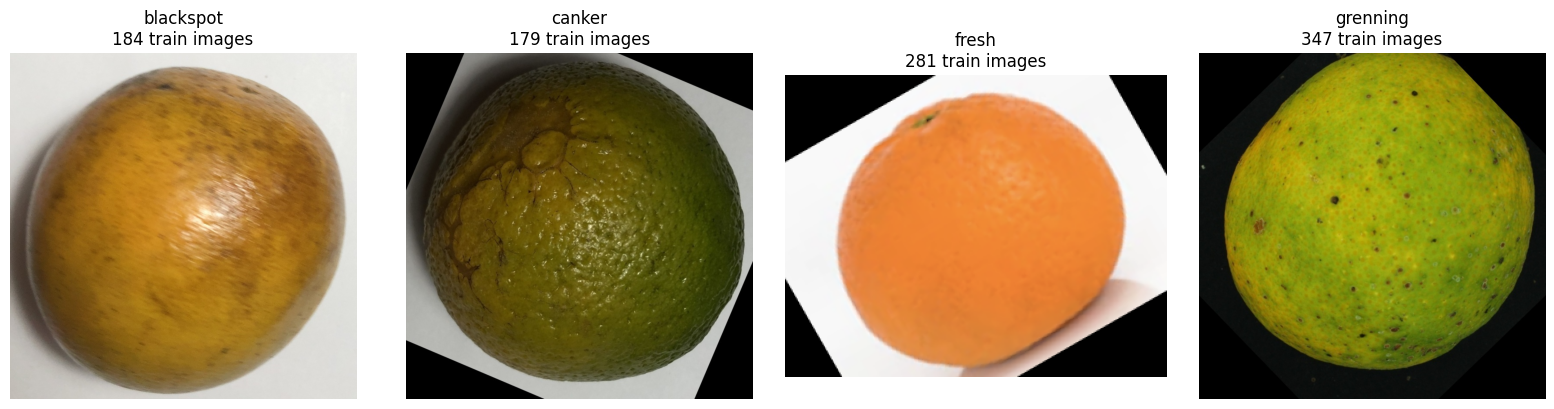

In [3]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

TRAIN_DIR = os.path.join(DATA_ROOT, 'train')
TEST_DIR = os.path.join(DATA_ROOT, 'test')
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def image_paths_by_class(root):
    result = {}
    for cls in sorted(os.listdir(root)):
        folder = os.path.join(root, cls)
        if os.path.isdir(folder):
            result[cls] = [os.path.join(folder, f) for f in sorted(os.listdir(folder))
                           if f.lower().endswith(IMG_EXTS)]
    return result

train_paths = image_paths_by_class(TRAIN_DIR)
test_paths = image_paths_by_class(TEST_DIR)
classes = sorted(set(train_paths) | set(test_paths))
assert classes, 'No class folders/images found.'

rows = []
for split, mapping in [('train', train_paths), ('test', test_paths)]:
    for cls in classes:
        rows.append({'split': split, 'class': cls, 'images': len(mapping.get(cls, []))})
counts_df = pd.DataFrame(rows)
display(counts_df.pivot(index='class', columns='split', values='images').fillna(0).astype(int))

train_counts = {c: len(train_paths.get(c, [])) for c in classes}
print('Classes:', classes)
print('Total training images:', sum(train_counts.values()))
print('Total test images:', sum(len(test_paths.get(c, [])) for c in classes))
print('Training imbalance ratio (largest/smallest non-zero class):',
      round(max(v for v in train_counts.values() if v) / min(v for v in train_counts.values() if v), 2))

fig, axes = plt.subplots(1, len(classes), figsize=(4*len(classes), 4))
if len(classes) == 1: axes = [axes]
for ax, cls in zip(axes, classes):
    candidates = train_paths.get(cls, [])
    if candidates:
        img = Image.open(candidates[0]).convert('RGB')
        ax.imshow(img); ax.set_title(f'{cls}\n{len(candidates)} train images'); ax.axis('off')
plt.tight_layout()
plt.show()


### Dataset observations

Use the counts and sample grid above in your report. Class counts alone do not prove bias, but imbalance can make the model favor common classes. Visual differences in lighting, camera angle, background, fruit size, and disease severity may also affect generalization. This notebook does not assume that such bias exists; inspect the displayed samples and describe only what you observe.

## 4. Prepare the classical model: HOG + SVM

In [4]:
from skimage.feature import hog
from skimage.color import rgb2gray
from skimage.transform import resize
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

IMG_SIZE_CLASSIC = (128, 128)

def hog_features(paths):
    feats = []
    for path in paths:
        with Image.open(path) as im:
            arr = np.asarray(im.convert('RGB'))
        arr = resize(arr, (*IMG_SIZE_CLASSIC, 3), anti_aliasing=True)
        gray = rgb2gray(arr)
        feat = hog(gray, orientations=9, pixels_per_cell=(8,8),
                   cells_per_block=(2,2), block_norm='L2-Hys',
                   transform_sqrt=True, feature_vector=True)
        feats.append(feat)
    return np.asarray(feats, dtype=np.float32)

X_train_paths = [p for c in classes for p in train_paths.get(c, [])]
y_train = [c for c in classes for _ in train_paths.get(c, [])]
X_test_paths = [p for c in classes for p in test_paths.get(c, [])]
y_test = [c for c in classes for _ in test_paths.get(c, [])]

print('Extracting HOG features...')
Xtr_hog = hog_features(X_train_paths)
Xte_hog = hog_features(X_test_paths)
svm_model = make_pipeline(StandardScaler(), SVC(C=5, kernel='rbf', class_weight='balanced', probability=True, random_state=42))
svm_model.fit(Xtr_hog, y_train)
svm_pred = svm_model.predict(Xte_hog)


Extracting HOG features...


## 5. Evaluate the HOG + SVM model

HOG + SVM — Accuracy: 0.8586 | Macro Precision: 0.8445 | Macro Recall: 0.8447 | Macro F1: 0.8439
              precision    recall  f1-score   support

   blackspot       0.71      0.77      0.74        22
      canker       0.70      0.64      0.67        22
       fresh       0.97      0.97      0.97        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.86        99
   macro avg       0.84      0.84      0.84        99
weighted avg       0.86      0.86      0.86        99



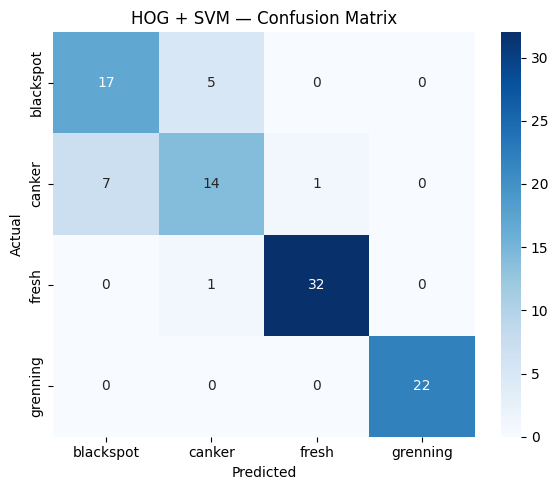

In [5]:
def evaluate_model(name, y_true, y_pred, labels):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average='macro', zero_division=0)
    print(f'{name} — Accuracy: {acc:.4f} | Macro Precision: {p:.4f} | Macro Recall: {r:.4f} | Macro F1: {f1:.4f}')
    print(classification_report(y_true, y_pred, labels=labels, target_names=labels, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    import seaborn as sns
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(f'{name} — Confusion Matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.tight_layout(); plt.show()
    return {'model': name, 'accuracy': acc, 'macro_precision': p, 'macro_recall': r, 'macro_f1': f1}

svm_metrics = evaluate_model('HOG + SVM', y_test, svm_pred, classes)


## 6. Train a MobileNetV2 transfer-learning classifier

In [6]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMG_SIZE_DL = (224, 224)
BATCH_SIZE = 32
EPOCHS_HEAD = 8
EPOCHS_FINE = 3

tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

def paths_and_labels(mapping, class_names):
    paths, labels = [], []
    for idx, cls in enumerate(class_names):
        for path in mapping.get(cls, []):
            paths.append(path); labels.append(idx)
    return paths, labels

tr_paths, tr_labels = paths_and_labels(train_paths, classes)
te_paths, te_labels = paths_and_labels(test_paths, classes)

def decode_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE_DL)
    return img, tf.cast(label, tf.int32)

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE)
    if training:
        aug = keras.Sequential([
            layers.RandomFlip('horizontal'),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10),
        ])
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(tr_paths, tr_labels, training=True)
test_ds = make_ds(te_paths, te_labels, training=False)

base_model = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE_DL, 3), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE_DL, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(len(classes), activation='softmax')(x)
dl_model = keras.Model(inputs, outputs)

dl_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2)
]
history_head = dl_model.fit(train_ds, validation_data=test_ds, epochs=EPOCHS_HEAD, callbacks=callbacks)

# Fine-tune only the last layers of the pretrained base.
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
dl_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_fine = dl_model.fit(train_ds, validation_data=test_ds, epochs=EPOCHS_FINE, callbacks=callbacks)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 69s 2s/step - accuracy: 0.8052 - loss: 0.5595 - val_accuracy: 0.8788 - val_loss: 0.2390 - learning_rate: 0.0010
Epoch 2/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.9395 - loss: 0.1665 - val_accuracy: 0.8889 - val_loss: 0.2053 - learning_rate: 0.0010
Epoch 3/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.9687 - loss: 0.1031 - val_accuracy: 0.9091 - val_loss: 0.1800 - learning_rate: 0.0010
Epoch 4/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.9748 - loss: 0.0839 - val_accuracy: 0.9192 - val_loss: 0.1588 - learning_rate: 0.0010
Epoch 5/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.9778 - loss: 0.0710 - val_accuracy: 0.9192 - val_loss: 0.1837 - learning_rate: 0.0010
Epoch 6/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step - accuracy: 0.9839 - loss: 0.0584 - val_accuracy: 0.9192 - val_loss: 0.1621 - learning_rate: 0.0010
Epoch 7/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 72s 2s/step - accura

## 7. Evaluate MobileNetV2

Note: the supplied `test/` set is used here for evaluation during the exercise. For a rigorous production experiment, do not tune model settings against the test set; use a separate validation split and reserve the test set for one final evaluation.

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step
MobileNetV2 Transfer Learning — Accuracy: 0.9192 | Macro Precision: 0.9219 | Macro Recall: 0.9091 | Macro F1: 0.9074
              precision    recall  f1-score   support

   blackspot       0.75      0.95      0.84        22
      canker       0.94      0.68      0.79        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.92        99
   macro avg       0.92      0.91      0.91        99
weighted avg       0.93      0.92      0.92        99



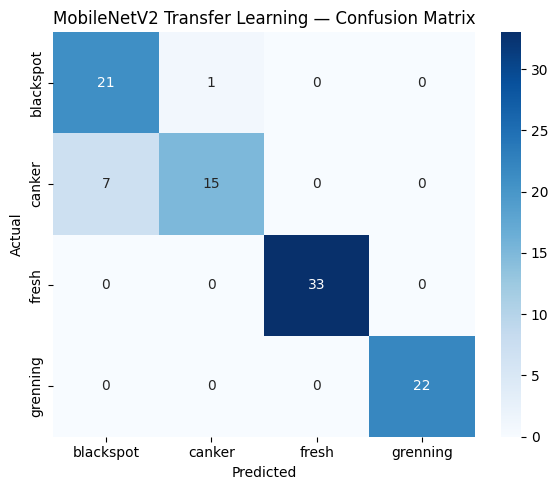

,accuracy,macro_precision,macro_recall,macro_f1
model,,,,
HOG + SVM,0.8586,0.8445,0.8447,0.8439
MobileNetV2 Transfer Learning,0.9192,0.9219,0.9091,0.9074


Best model by macro F1-score: MobileNetV2 Transfer Learning


In [7]:
dl_probs = dl_model.predict(test_ds)
dl_pred_idx = np.argmax(dl_probs, axis=1)
dl_pred = [classes[i] for i in dl_pred_idx]
dl_metrics = evaluate_model('MobileNetV2 Transfer Learning', y_test, dl_pred, classes)

comparison = pd.DataFrame([svm_metrics, dl_metrics]).set_index('model')
display(comparison.style.format('{:.4f}'))
best_model_name = comparison['macro_f1'].idxmax()
print('Best model by macro F1-score:', best_model_name)


## 8. Example prediction

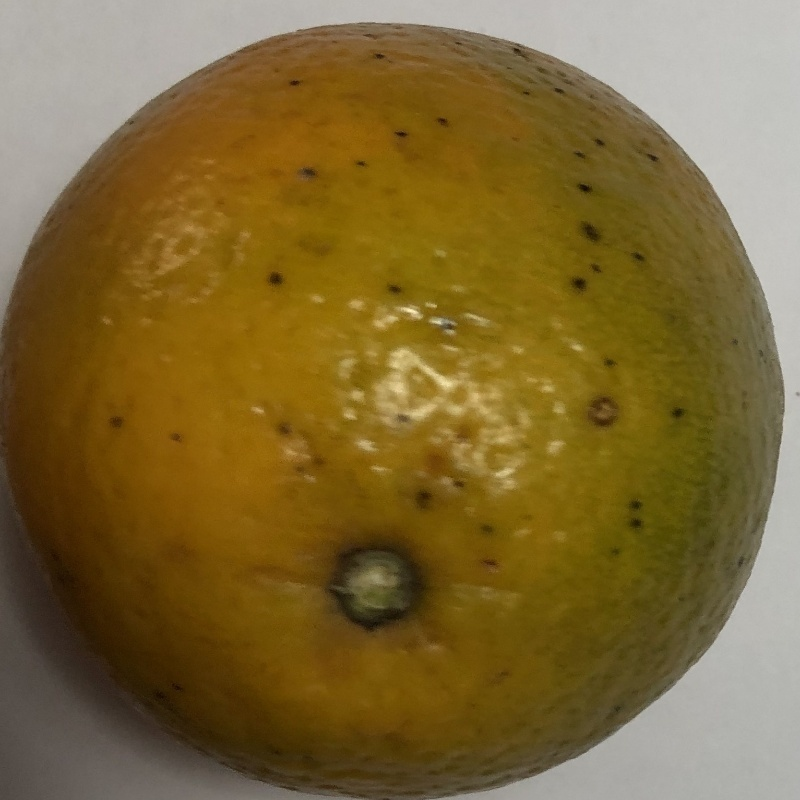

HOG + SVM prediction: blackspot
MobileNetV2 prediction: blackspot (model confidence: 99.6%)


In [8]:
def predict_one(image_path):
    with Image.open(image_path) as im:
        img = im.convert('RGB')
        display(img)
        # Classical prediction
        h = hog_features([image_path])
        classic_label = svm_model.predict(h)[0]
        # Deep-learning prediction
        arr = np.asarray(img.resize(IMG_SIZE_DL), dtype=np.float32)[None, ...]
        probs = dl_model.predict(arr, verbose=0)[0]
        dl_label = classes[int(np.argmax(probs))]
        confidence = float(np.max(probs))
    print('HOG + SVM prediction:', classic_label)
    print('MobileNetV2 prediction:', dl_label, f'(model confidence: {confidence:.1%})')

# Example: first image in the test set. Change to any image path if desired.
if X_test_paths:
    predict_one(X_test_paths[0])


## 9. Generate assignment report and answer the four questions

In [9]:
from datetime import datetime

def pct(x): return f'{x:.2%}'
rows = []
for m in [svm_metrics, dl_metrics]:
    rows.append(f"| {m['model']} | {pct(m['accuracy'])} | {pct(m['macro_precision'])} | {pct(m['macro_recall'])} | {pct(m['macro_f1'])} |")
comparison_md = '\n'.join(rows)

# Evidence-based answer text
if dl_metrics['macro_f1'] > svm_metrics['macro_f1']:
    winner_reason = ('MobileNetV2 achieved the higher macro F1-score on the provided test set. '
                     'Transfer learning can reuse visual features learned from large image datasets, '
                     'which may help when the labelled dataset is relatively small.')
elif dl_metrics['macro_f1'] < svm_metrics['macro_f1']:
    winner_reason = ('HOG + SVM achieved the higher macro F1-score on the provided test set. '
                     'For this dataset, handcrafted edge/shape features with an SVM generalized better '
                     'than the transfer-learning model under the current training setup.')
else:
    winner_reason = ('Both approaches achieved the same macro F1-score on the provided test set. '
                     'Consider inference time, model size, per-class errors, and further validation before selecting one.')

report = f"""# Image Classification Report — GreenPod Labs Assignment

## Dataset and scope
The provided archive is named `Orange Dataset.zip` and contains the classes: {', '.join(classes)}.
This differs from the assignment brief shown in the supplied screenshot, which describes avocado ripening stages. Confirm that the correct dataset was supplied before submission.

Training images: {len(tr_paths)}
Test images: {len(te_paths)}
Classes: {len(classes)}
Training class counts: {train_counts}

## Dataset quality, imbalance, and possible bias
Class counts are shown above and in the notebook. The training data may be imbalanced; the imbalance ratio (largest/smallest class) is {max(train_counts.values()) / min(v for v in train_counts.values() if v):.2f}. Image classification may also be affected by illumination, background, camera angle, fruit variety, and severity of visible symptoms. These are potential sources of bias and should be verified by inspecting representative examples. The dataset's origin and collection conditions are not documented in the archive, so demographic/geographic or capture-setting bias cannot be ruled out.

## Approaches
1. **HOG + SVM:** Histogram of Oriented Gradients captures local edge/shape patterns; an SVM separates the feature vectors. This is a relatively lightweight baseline and can work well when visual patterns are consistent.
2. **MobileNetV2 transfer learning:** A pretrained convolutional neural network extracts general visual features. A new classification head is trained on this dataset, followed by limited fine-tuning. This is suitable for small datasets but can overfit and requires more compute.

## Evaluation
Metrics below are computed from the provided test folder when this notebook is run.

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
{comparison_md}

**Selected model by macro F1:** {best_model_name}.
{winner_reason}

Macro-averaged metrics give each class equal weight, which is useful when class counts differ. The confusion matrices and per-class classification reports should be reviewed to identify classes that are often confused.

## Mandatory questions

### 1. In production, how would your model perform?
The notebook's test-set scores are a first estimate, not a guarantee of production performance. Real-world performance may be lower if images have different lighting, backgrounds, camera devices, fruit varieties, or disease severity than the training data. Before deployment, test on independently collected images, monitor per-class precision/recall and prediction confidence, and periodically review errors and drift. For an automated sorting line, uncertain predictions should be sent for human inspection rather than forcing a potentially unsafe classification.

### 2. What are the drawbacks of your model?
HOG + SVM relies on handcrafted visual features and may struggle with complex texture changes, unusual angles, occlusion, and background variation. MobileNetV2 is more computationally demanding, depends on pretrained weights, can overfit a small dataset, and may be sensitive to domain shift. Both models are limited by label quality and the representativeness of the supplied images. Test-set size is also modest, so scores have uncertainty.

### 3. If given more time, what would you improve?
- Confirm and document the intended target labels and dataset provenance.
- Collect more images across lighting, camera, background, fruit variety, and symptom severity.
- Use a stratified train/validation/test strategy and keep the test set untouched during tuning.
- Tune learning rate, augmentation, SVM parameters, and class weights using validation data.
- Inspect misclassified images, add explainability visualizations, and test calibration.
- Measure latency and memory on the intended production hardware; add human review for low-confidence predictions.

### 4. Where did you spend more time during the assignment?
The main effort was spent on preparing and auditing the image dataset, building two different approaches, and comparing their errors using class-wise metrics and confusion matrices. The aim was not just to maximize accuracy but to understand where each model fails and how suitable it is for real-world use.

## Reproducibility
Run all notebook cells in order. The table above is generated from actual model predictions; do not replace it with guessed results. Save the notebook with outputs after execution before submitting.
"""

with open('/content/GreenPod_Assignment_Report.md', 'w', encoding='utf-8') as f:
    f.write(report)
print(report)


# Image Classification Report — GreenPod Labs Assignment

## Dataset and scope
The provided archive is named `Orange Dataset.zip` and contains the classes: blackspot, canker, fresh, grenning.
This differs from the assignment brief shown in the supplied screenshot, which describes avocado ripening stages. Confirm that the correct dataset was supplied before submission.

Training images: 991  
Test images: 99  
Classes: 4  
Training class counts: {'blackspot': 184, 'canker': 179, 'fresh': 281, 'grenning': 347}

## Dataset quality, imbalance, and possible bias
Class counts are shown above and in the notebook. The training data may be imbalanced; the imbalance ratio (largest/smallest class) is 1.94. Image classification may also be affected by illumination, background, camera angle, fruit variety, and severity of visible symptoms. These are potential sources of bias and should be verified by inspecting representative examples. The dataset's origin and collection conditions are not document

## 10. Save deliverables

Download the generated report and save the notebook with outputs. The notebook file itself is the main reproducible deliverable. Do not claim results until both models finish running and the metrics are displayed.

In [10]:
from google.colab import files
files.download('/content/GreenPod_Assignment_Report.md')
# In Colab, use File → Download → Download .ipynb to download this notebook with outputs.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>